# Jump Model (JM) Market Regime

Minute-frequency market regime prediction with a Statistical Jump Model.

This notebook consolidates the JM pipeline end to end: data preparation, market-state prediction, in-sample / out-of-sample backtesting, full-period evaluation, XGBoost-based regime prediction, results export, and Combinatorial Purged Cross-Validation (CPCV).

# 1. Data Preparation

## 1.1 Data Inspection

In [1]:
#导包
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.cluster import KMeans

In [2]:
df_min = pd.read_csv('../data/kline_im.csv')
df_min.set_index('DateTime', inplace=True)
df_min

,Unnamed: 0,day,open,high,low,close,vol,amount,twap,rsrs,...,max_ret_index,min_ret_index,max_amount_index,increase_kline_ratio,decrease_kline_ratio,equal_kline_ratio,vwap_ema_1,vwap_ema_2,pct,slippage
DateTime,,,,,,,,,,,,,,,,,,,,,
2022/7/22 9:30,0,2022/7/22,5041.799985,5076.999985,5032.799985,5047.599985,2597,3670919280,5062.106651,0.514591,...,1,13,0,0.533333,0.400000,0.066667,1.411248e+06,1.413470e+06,-0.011966,1.981140e-07
2022/7/22 9:45,1,2022/7/22,5048.199985,5048.599985,4976.799985,4987.199985,2292,3214320560,5001.066651,0.973886,...,7,2,5,0.200000,0.800000,0.000000,1.399274e+06,1.402205e+06,0.003930,2.005133e-07
2022/7/22 10:00,2,2022/7/22,4987.199985,5016.199985,4984.399985,5006.799985,1422,1994239360,5004.039985,0.818966,...,0,13,13,0.666667,0.266667,0.066667,1.403338e+06,1.402740e+06,0.006551,1.997284e-07
2022/7/22 10:15,3,2022/7/22,5008.199985,5045.599985,5000.799985,5039.599985,1392,1957681760,5022.933318,1.042818,...,10,0,11,0.666667,0.333333,0.000000,1.408995e+06,1.406698e+06,-0.003730,1.984284e-07
2022/7/22 10:30,4,2022/7/22,5039.399985,5039.599985,5016.799985,5020.799985,1118,1572904440,5025.826651,1.083749,...,3,2,11,0.333333,0.666667,0.000000,1.406104e+06,1.406730e+06,-0.005577,1.991714e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026/3/20 13:45,11,2026/3/20,7660.000000,7666.200000,7642.000000,7643.800000,5447,8336630920,7652.946667,1.085567,...,8,9,1,0.400000,0.600000,0.000000,1.529395e+06,1.530344e+06,-0.001465,1.308250e-07
2026/3/20 14:00,12,2026/3/20,7643.800000,7664.800000,7625.600000,7632.600000,6613,10109080200,7643.773333,1.033320,...,6,8,9,0.400000,0.533333,0.066667,1.526780e+06,1.528041e+06,-0.000524,1.310170e-07
2026/3/20 14:15,13,2026/3/20,7633.000000,7643.800000,7619.400000,7628.600000,5162,7878171720,7631.746667,0.822899,...,2,4,2,0.466667,0.533333,0.000000,1.525637e+06,1.526077e+06,-0.002779,1.310857e-07


## 1.2 Feature Engineering

In [3]:
# 波动率特征
def get_dd(ret, hl):
    downside_ret = ret.copy()
    downside_ret[downside_ret > 0] = 0
    return np.sqrt((downside_ret**2).ewm(halflife=hl).mean())

In [4]:
# 收益率特征
df_min['return'] = np.log(df_min['close']) - np.log(df_min['close'].shift(1))
df_min['ewma_ret'] = df_min['return'].ewm(halflife=120).mean()
# 波动率特征
df_min['dd20'] = get_dd(df_min['return'], 20)
df_min['dd60'] = get_dd(df_min['return'], 60)
df_min['dd120'] = get_dd(df_min['return'], 120)
df_min['dd20_60'] = df_min['dd20'] - df_min['dd60']
df_min['dd60_120'] = df_min['dd60'] - df_min['dd120']
df_min['dd20_120'] = df_min['dd20'] - df_min['dd120']
df_min['f1'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(1))

# 五日对数成交量差
df_min['f2'] = np.log(df_min['vol']) - np.log(df_min['vol'].shift(5))

# 五日对数收盘价差 (五日动量)
df_min['f4'] = np.log(df_min['close']) - np.log(df_min['close'].shift(5))

# 当日对数高低价差 (当日内波动)
df_min['f5'] = np.log(df_min['high']) - np.log(df_min['low'])
df_min = df_min.drop(df_min.index[:5])
df_min.index = pd.to_datetime(df_min.index)
df_min.index

DatetimeIndex(['2022-07-22 10:45:00', '2022-07-22 11:00:00',
               '2022-07-22 11:15:00', '2022-07-22 13:00:00',
               '2022-07-22 13:15:00', '2022-07-22 13:30:00',
               '2022-07-22 13:45:00', '2022-07-22 14:00:00',
               '2022-07-22 14:15:00', '2022-07-22 14:30:00',
               ...
               '2026-03-20 11:00:00', '2026-03-20 11:15:00',
               '2026-03-20 13:00:00', '2026-03-20 13:15:00',
               '2026-03-20 13:30:00', '2026-03-20 13:45:00',
               '2026-03-20 14:00:00', '2026-03-20 14:15:00',
               '2026-03-20 14:30:00', '2026-03-20 14:45:00'],
              dtype='datetime64[ns]', name='DateTime', length=14174, freq=None)

## 1.3 Feature Standardization

In [5]:
# 滚动窗口标准化
window = 336
# features = ["f1", "f2", "return", "f4", "f5"]
features = ["ewma_ret","dd20", "dd60", "dd120", "dd20_60", "dd60_120", "dd20_120", "f1", "f2", "return", "f4", "f5"]
# 计算滚动均值和滚动标准差
rolling_mean = df_min[features].rolling(window=window).mean()
rolling_std = df_min[features].rolling(window=window).std()


# 执行滚动标准化
# 前 251 行会因为窗口不足产生 NaN
df_feature_rolling = (df_min[features] - rolling_mean) / rolling_std
df_train_norm = df_feature_rolling.loc[:'2024-09-30 15:00:00'].dropna()
df_test_norm = df_feature_rolling.loc['2024-10-01- 09:30:00':]
X_train = df_train_norm
X_test = df_test_norm
X_train

,ewma_ret,dd20,dd60,dd120,dd20_60,dd60_120,dd20_120,f1,f2,return,f4,f5
DateTime,,,,,,,,,,,,
2022-08-22 10:30:00,0.291700,-0.282218,-0.990084,-1.055640,0.887055,-0.587488,0.509491,-0.235593,-0.458570,0.325293,0.303854,0.020913
2022-08-22 10:45:00,0.316641,-0.308730,-1.000283,-1.063609,0.837352,-0.606525,0.466842,-0.392599,-1.743519,0.495830,1.825330,-0.074224
2022-08-22 11:00:00,0.313134,-0.335339,-1.009448,-1.069790,0.788879,-0.625311,0.425089,-0.490779,-1.527475,0.029064,0.510186,-0.474419
2022-08-22 11:15:00,0.336191,-0.360471,-1.021781,-1.081591,0.742368,-0.643633,0.384847,1.084143,-0.531036,0.351455,0.973073,-0.294397
2022-08-22 13:00:00,0.323604,-0.384915,-1.032220,-1.090621,0.697832,-0.661051,0.346279,-1.013599,-0.681060,-0.120642,0.544520,-0.607748
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-09-30 13:45:00,3.925985,2.538743,3.175212,3.511182,1.832273,2.710913,2.154467,-3.713275,-3.304020,-0.154572,1.041712,-1.201911
2024-09-30 14:00:00,3.806232,2.401341,3.060944,3.388435,1.670654,2.608374,2.009083,-3.009369,-4.754675,-0.155117,0.297635,-1.199239
2024-09-30 14:15:00,3.694725,2.270200,2.952773,3.273136,1.514498,2.510143,1.869205,6.839381,-0.734854,-0.154770,0.464132,-0.241714


In [6]:
# 过滤出原表（用于回测计算）
df_train_rolling = df_min.loc[df_train_norm.index]
df_test_rolling = df_min.loc[df_test_norm.index]
df_test_rolling

,Unnamed: 0,day,open,high,low,close,vol,amount,twap,rsrs,...,dd20,dd60,dd120,dd20_60,dd60_120,dd20_120,f1,f2,f4,f5
DateTime,,,,,,,,,,,,,,,,,,,,,
2024-10-08 09:30:00,8528,2024/10/8,5283.599998,5283.599998,5245.399998,5277.399998,13110,16614235520,5281.599998,-6.430000e-27,...,0.004317,0.003800,0.003410,0.000516,0.000390,0.000906,4.218440,3.268524,0.112897,0.007256
2024-10-08 09:45:00,8529,2024/10/8,5279.599998,5283.599998,5269.599998,5283.599998,2984,3781533480,5283.599998,7.234154e-26,...,0.004242,0.003778,0.003400,0.000464,0.000378,0.000842,-1.480111,3.436672,0.114071,0.002653
2024-10-08 10:00:00,8530,2024/10/8,5283.599998,5283.599998,5147.199998,5149.199998,11814,14874581080,5259.319998,5.484912e-01,...,0.006325,0.004662,0.003914,0.001662,0.000748,0.002411,1.376021,0.795184,0.088305,0.026155
2024-10-08 10:15:00,8531,2024/10/8,5145.999998,5283.199998,5129.199998,5136.799998,12898,16182979600,5225.306665,6.792863e-01,...,0.006232,0.004643,0.003907,0.001589,0.000736,0.002325,0.087787,3.931438,0.085894,0.029582
2024-10-08 10:30:00,8532,2024/10/8,5135.399998,5162.399998,4839.599998,5153.999998,17691,21536400280,5050.279998,6.650614e-01,...,0.006125,0.004616,0.003896,0.001509,0.000720,0.002229,0.315984,4.518121,0.089236,0.064570
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-20 13:45:00,11,2026/3/20,7660.000000,7666.200000,7642.000000,7643.800000,5447,8336630920,7652.946667,1.085567e+00,...,0.003536,0.003249,0.003124,0.000287,0.000125,0.000412,0.074489,-0.393088,-0.008338,0.003162
2026-03-20 14:00:00,12,2026/3/20,7643.800000,7664.800000,7625.600000,7632.600000,6613,10109080200,7643.773333,1.033320e+00,...,0.003486,0.003234,0.003117,0.000251,0.000117,0.000369,0.193972,-0.676988,-0.016863,0.005127
2026-03-20 14:15:00,13,2026/3/20,7633.000000,7643.800000,7619.400000,7628.600000,5162,7878171720,7631.746667,8.228993e-01,...,0.003427,0.003216,0.003108,0.000211,0.000108,0.000319,-0.247713,-0.534450,-0.010769,0.003197


# 2. Model

## 2.1 Jump Model Training

In [7]:
from cpcv import fit_sjm, predict_test_set


In [8]:
# 模型训练+拟合
lam = 150
train_states, theta, V_grid = fit_sjm(X_train.values, K=4, lam=lam, max_iter=1000)
test_states = predict_test_set(X_test.values, theta, lam, train_states, V_grid)
print("train_states:", train_states[:100])
print("theta:", theta)
print("V_grid:", V_grid)
print("test_states:", test_states[100:200])

df_train_plot = df_train_rolling.copy() 
df_test_plot = df_test_rolling.copy()   
df_train_plot['state'] = train_states
df_test_plot['state'] = test_states

最大迭代次数： 7
最大迭代次数： 7
train_states: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
theta: [[-8.14930326e-01  1.90533490e-01 -3.61325838e-01 -7.97985281e-01
   7.16102781e-01  5.71344442e-01  7.37485173e-01  1.82461863e-03
   5.11310833e-03 -7.52400436e-02 -1.73628329e-01  3.34206277e-02]
 [-2.01264013e-01  6.38384961e-01  1.14315183e+00  1.22222338e+00
  -7.73833426e-02  7.55723119e-01  2.19582115e-01 -3.28072565e-03
  -1.20230698e-03  5.66560712e-02  1.29110219e-01  2.42038008e-01]
 [ 7.39538177e-01 -1.06320300e+00 -1.19173711e+00 -1.10276416e+00
  -6.27605165e-01 -1.04172781e+00 -8.03803268e-01 -1.37889139e-03
  -1.08346336e-02  3.60768012e-02  8.84126192e-02 -3.53809893e-01]
 [-1.68924122e+00  2.54162772e+00  2.53560513e+00  2.10039821e+00
   1.97670764e+00  2.60773602e+00  2.25175687e+00 -1.56826469e-03
   3.27641881e-03 -1.06633

# 3. Backtest Visualization

## 3.1 In-Sample State Classification

In [9]:
# 计算净值
def cal_net_values(post:np.array,ret:np.array) -> np.array:
    '''计算净值序列
    pos: 仓位
    ret:未来1个周期的收益率'''
    fee = 0 # 仓位每次变动的磨损0.0005
    position_changes = np.hstack((post[0],np.diff(post)))# 拼接初始仓位并记录此时的手续费，后面的时间使用diff的
    ret_array = post*ret - abs(position_changes*fee)
    net_values = 1+(ret_array).cumsum()
    return net_values, ret_array  # 返回净值序列、收益率序列

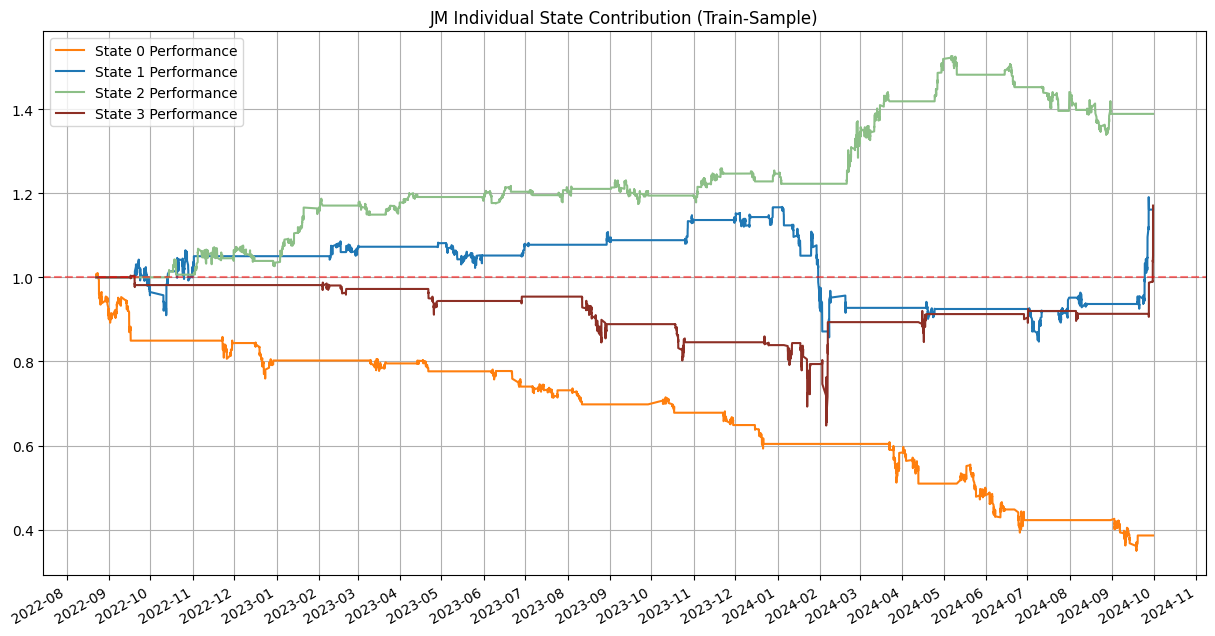

In [10]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(len(V_grid[0])):
    df_train_sample = df_train_plot.copy()
    net = df_train_sample['pct'].astype(float).values
    signal = (df_train_sample['state'] == i).astype(float).values
    net_values, _ = cal_net_values(signal, net)
    plot_dates = df_train_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("JM Individual State Contribution (Train-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

## 3.2 Out-of-Sample State Classification

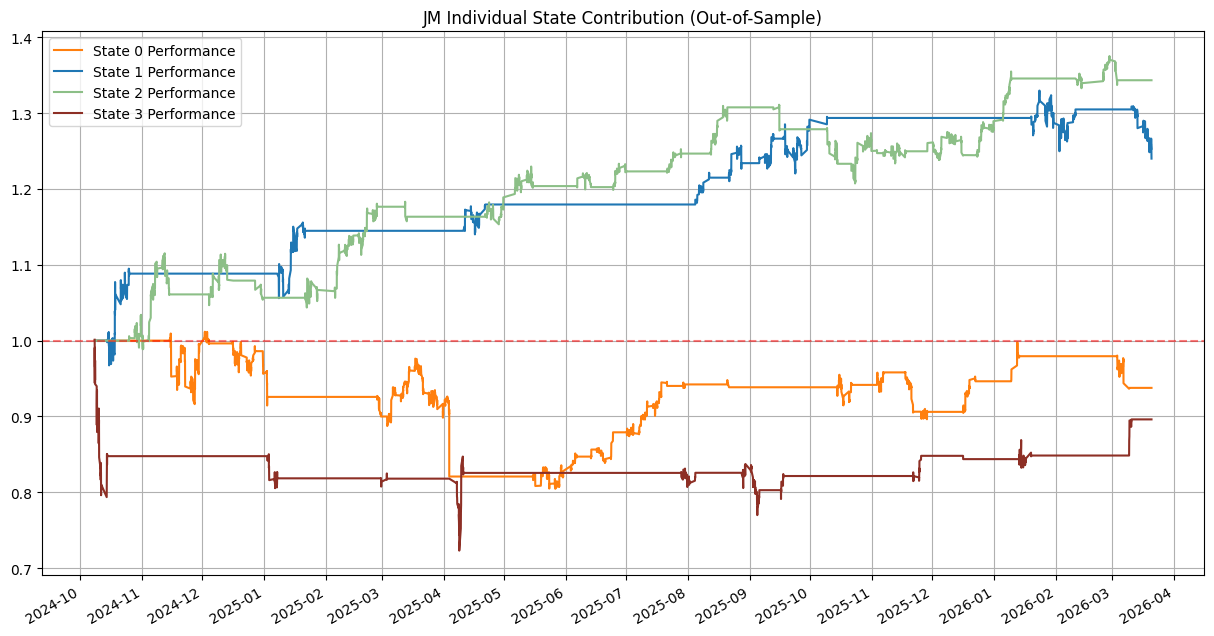

In [11]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(len(V_grid[0])):
    df_test_sample = df_test_plot.copy()
    net = df_test_sample['pct'].astype(float).values
    signal = (df_test_sample['state'] == i).astype(float).values
    net_values, _ = cal_net_values(signal, net) 
    plot_dates = df_test_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("JM Individual State Contribution (Out-of-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

## 3.3 Return Backtest Evaluation

In [12]:
# 计算最大回撤
def calculate_mdd(cum_series):
    """
    计算净值曲线的最大回撤及其结束时间点
    """
    # 转换为 numpy 数组方便计算
    nav = np.array(cum_series)
    # 计算历史滚动最高点
    peaks = np.maximum.accumulate(nav)
    # 计算回撤序列 (当前值 / 历史最高值 - 1)
    drawdowns = (nav - peaks) / peaks
    # 找到最大回撤值（最小值）
    mdd_value = np.min(drawdowns)
    # 找到最大回撤发生的索引位置（即回撤结束/最低点的位置）
    mdd_idx = np.argmin(drawdowns)
    
    return mdd_value, mdd_idx
# 算上换手率
def cal_net_values(post:np.array,ret:np.array) -> np.array:
    '''计算净值序列
    pos: 仓位
    ret:未来1个周期的收益率'''
    fee = 0.0005 # 仓位每次变动的磨损
    position_changes = np.hstack((post[0],np.diff(post)))# 拼接初始仓位并记录此时的手续费，后面的时间使用diff的
    ret_array = post*ret - abs(position_changes*fee)
    net_values = 1+(ret_array).cumsum()
    return net_values, ret_array  # 返回净值序列、收益率序列

# 夏普计算
def calculate_sharpe(strat_ret, rf=0, periods=252):
    '''
    strat_ret: 策略收益率序列
    rf: 无风险利率 (年化)（市场的年化收益率）
    periods: 年度交易周期数 
    '''
    # 计算超额收益 (Daily Excess Return)
    excess_ret = strat_ret - (rf / periods)
    
    # 计算均值和标准差
    mean_ret = np.mean(excess_ret)
    std_ret = np.std(excess_ret)
    
    # 计算原始夏普 (非年化)
    if std_ret == 0:
        return 0
    sharpe = mean_ret / std_ret
    
    # 年化处理
    annual_sharpe = sharpe * np.sqrt(periods)
    
    return annual_sharpe


【市场基准】最大回撤: -66.83% | 发生时间: 2024-02-05 10:30:00
【JM策略】最大回撤: -20.58% | 发生时间: 2024-02-07 14:00:00


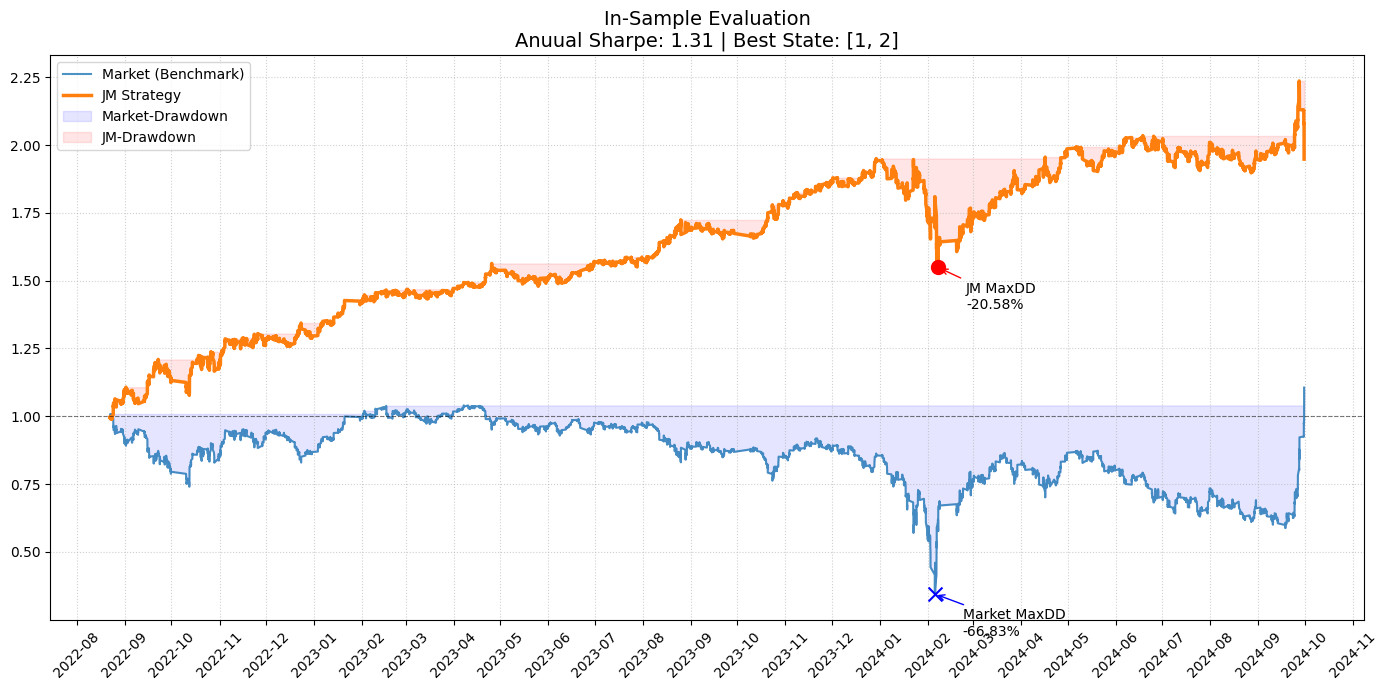

【市场基准】最大回撤: -22.71% | 发生时间: 2025-04-08 14:45:00
【JM策略】最大回撤: -7.92% | 发生时间: 2025-07-21 09:45:00


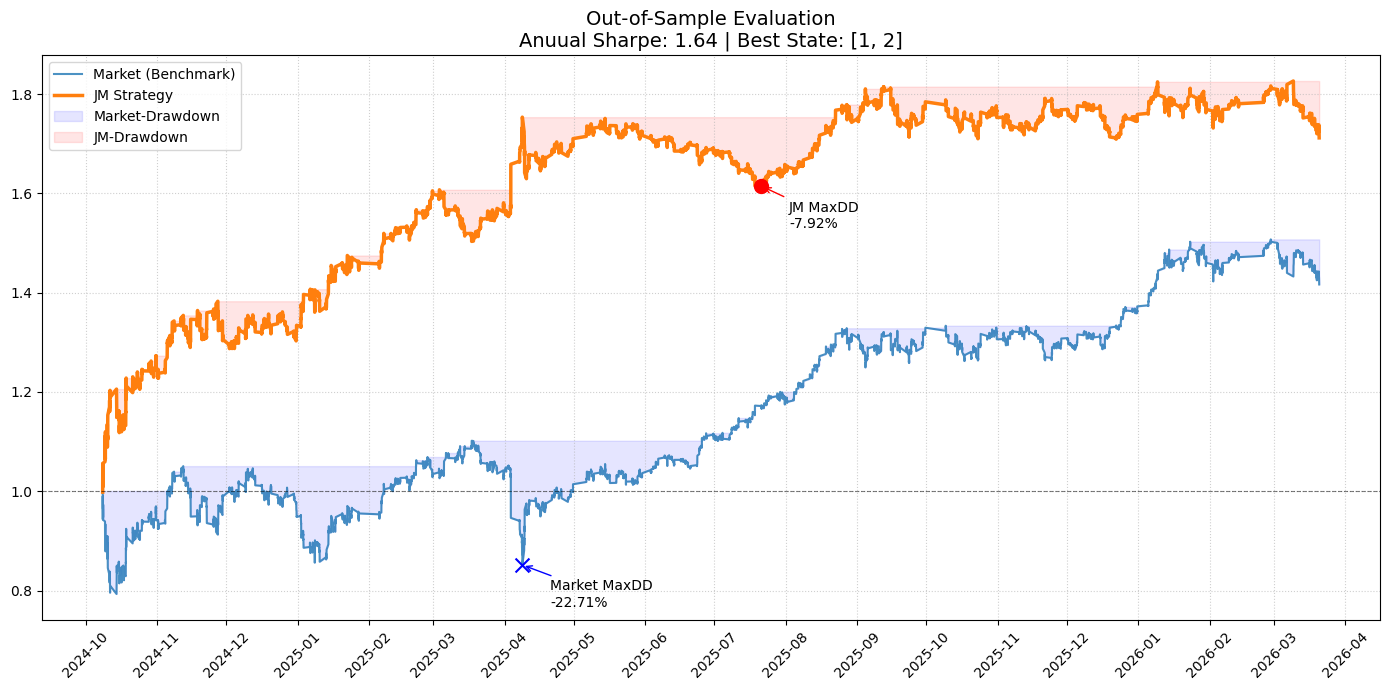

In [13]:
def plot_backtest(df_input, title, use_state):
    # 1. 深拷贝并预处理，确保无警告
    df = df_input.copy()
    df.index = pd.to_datetime(df.index)
    ret_map = {0:-1, 1:1,2:1, 3:-1}
    pos_market = np.ones_like(df['state'].values)
    df["pos"] = df['state'].map(ret_map)
    pos_array = df['pos'].astype(float).values # state
    # 计算策略收益序列
    res_values = df['pct'].astype(float).values

    net_values, _ = cal_net_values(pos_array, res_values)
    market_values, _ = cal_net_values(pos_market, res_values)

    df['net_values'] = net_values
    net_ret_date = df['net_values'].groupby(df.index.date).last().diff()

    plot_dates = list(df.index)

    m_mdd_val, m_mdd_idx = calculate_mdd(market_values)
    s_mdd_val, s_mdd_idx = calculate_mdd(net_values)

    # 获取对应的日期（从 plot_dates 中提取）
    m_mdd_date = plot_dates[m_mdd_idx]
    s_mdd_date = plot_dates[s_mdd_idx]

    annual_sharpe = calculate_sharpe(net_ret_date)
    

    print(f"【市场基准】最大回撤: {m_mdd_val:.2%} | 发生时间: {m_mdd_date}")
    print(f"【JM策略】最大回撤: {s_mdd_val:.2%} | 发生时间: {s_mdd_date}")

    plt.figure(figsize=(14, 7), dpi=100)
    
    # 使用你指定的蓝色和橙色
    plt.plot(plot_dates, market_values, color='#1f77b4', label='Market (Benchmark)', alpha=0.8)
    plt.plot(plot_dates, net_values, color='#ff7f0e', label='JM Strategy', linewidth=2.5)
    
    # 绘制最大回撤区域（可选，更专业）
    market_peak = np.maximum.accumulate(market_values)
    strategy_peak = np.maximum.accumulate(net_values)
    plt.fill_between(plot_dates, market_values, market_peak, color='blue', alpha=0.1, label='Market-Drawdown')
    plt.fill_between(plot_dates, net_values, strategy_peak, color='red', alpha=0.1, label='JM-Drawdown')

    # 起始点辅助线
    plt.axhline(1, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
    
    # 标题与统计信息
    plt.title(f"{title}\nAnuual Sharpe: {annual_sharpe:.2f} | Best State: {use_state}", fontsize=14)
    
    # 坐标轴优化
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper left')
    
    plt.tight_layout()
    plt.scatter(m_mdd_date, market_values[m_mdd_idx], color='blue', s=100, marker='x', 
            label=f'Market MaxDD: {m_mdd_val:.2%}', zorder=5)

    # 标记策略最大回撤点
    plt.scatter(s_mdd_date, net_values[s_mdd_idx], color='red', s=100, marker='o', 
                label=f'JM MaxDD: {s_mdd_val:.2%}', zorder=5)
    plt.annotate(f'Market MaxDD\n{m_mdd_val:.2%}', 
                xy=(m_mdd_date, market_values[m_mdd_idx]), 
                xytext=(20, -30), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='blue'))
    plt.annotate(f'JM MaxDD\n{s_mdd_val:.2%}', 
                xy=(s_mdd_date, net_values[s_mdd_idx]), 
                xytext=(20, -30), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='red'))
    plt.show()
# 状态总数
states = len(V_grid[0])
# 训练集确定best_state
# best_state = df_train_plot.groupby('state')['f3'].mean().idxmax()
buy_state = [1,2]
plot_backtest(df_train_plot, "In-Sample Evaluation", buy_state)
plot_backtest(df_test_plot, "Out-of-Sample Evaluation", buy_state)

## 3.4 Full-Period Backtest

In [14]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
df_full = pd.read_csv('../data/kline_im.csv')
df_full.set_index('DateTime', inplace=True)
# 收益率特征
df_full['vol_log_ret_1p'] = np.log(df_full['vol']) - np.log(df_full['vol'].shift(1))
# 五日对数成交量差
df_full['vol_log_ret_5p'] = np.log(df_full['vol']) - np.log(df_full['vol'].shift(5))
# 一日对数收盘价差（一日动量）
df_full['close_log_ret_1p'] = np.log(df_full['close']) - np.log(df_full['close'].shift(1))
# 五日对数收盘价差 (五日动量)
df_full['close_log_ret_5p'] = np.log(df_full['close']) - np.log(df_full['close'].shift(5))
# 当日对数高低价差 (当日内波动)
df_full['intraday_range_log'] = np.log(df_full['high']) - np.log(df_full['low'])
# 收益率特征
df_full['ewma_ret'] = df_full['close_log_ret_1p'].ewm(halflife=120).mean()
# 波动率特征
df_full['dd20'] = get_dd(df_full['close_log_ret_1p'], 20)
df_full['dd60'] = get_dd(df_full['close_log_ret_1p'], 60)
df_full['dd120'] = get_dd(df_full['close_log_ret_1p'], 120)

df_full['dd20_60'] = df_full['dd20'] - df_full['dd60']
df_full['dd60_120'] = df_full['dd60'] - df_full['dd120']
df_full['dd20_120'] = df_full['dd20'] - df_full['dd120']
df_full = df_full.drop(df_full.index[:5])
df_full.index = pd.to_datetime(df_full.index)

# 滚动窗口标准化
window = 336
features = ["ewma_ret","dd20", "dd60", "dd120", "dd20_60", "dd60_120", "dd20_120", "vol_log_ret_1p", "vol_log_ret_5p", "close_log_ret_1p", "close_log_ret_5p", "intraday_range_log"]
# 计算滚动均值和滚动标准差
rolling_mean = df_full[features].rolling(window=window).mean()
rolling_std = df_full[features].rolling(window=window).std()
# 执行滚动标准化
# 前 251 行会因为窗口不足产生 NaN
df_feature_rolling = (df_full[features] - rolling_mean) / rolling_std
df_train_norm = df_feature_rolling.loc[:'2024-09-30 15:00:00'].dropna()
df_test_norm = df_feature_rolling.dropna()
df_train_rolling = df_full.loc[df_train_norm.index]
df_test_rolling = df_full.loc[df_test_norm.index]

In [15]:
# 模型训练+拟合
X_train = df_train_norm.values
X_test = df_test_norm.values
lam = 150
train_states, theta, V_grid = fit_sjm(X_train, K=4, lam=lam, max_iter=1000)
test_states = predict_test_set(X_test, theta, lam, train_states, V_grid)
print("theta:", theta)
print("V_grid:", V_grid)

df_train_plot = df_train_rolling.copy() 
df_test_plot = df_test_rolling.copy()   
df_train_plot['state'] = train_states
df_test_plot['state'] = test_states

最大迭代次数： 7
最大迭代次数： 7
theta: [[-8.14930326e-01  1.90533490e-01 -3.61325838e-01 -7.97985281e-01
   7.16102781e-01  5.71344442e-01  7.37485173e-01  1.82461863e-03
   5.11310833e-03 -7.52400436e-02 -1.73628329e-01  3.34206277e-02]
 [-2.01264013e-01  6.38384961e-01  1.14315183e+00  1.22222338e+00
  -7.73833426e-02  7.55723119e-01  2.19582115e-01 -3.28072565e-03
  -1.20230698e-03  5.66560712e-02  1.29110219e-01  2.42038008e-01]
 [ 7.39538177e-01 -1.06320300e+00 -1.19173711e+00 -1.10276416e+00
  -6.27605165e-01 -1.04172781e+00 -8.03803268e-01 -1.37889139e-03
  -1.08346336e-02  3.60768012e-02  8.84126192e-02 -3.53809893e-01]
 [-1.68924122e+00  2.54162772e+00  2.53560513e+00  2.10039821e+00
   1.97670764e+00  2.60773602e+00  2.25175687e+00 -1.56826469e-03
   3.27641881e-03 -1.06633280e-01 -2.95914701e-01  1.16830826e+00]]
V_grid: [[3.99388751e+00 1.40630358e+01 5.60445337e+00 5.08524520e+01]
 [1.50245779e+01 3.41585214e+01 1.68024222e+01 1.09940255e+02]
 [2.19303298e+01 5.11846299e+01 2.39705523

## 3.5 Save Data

In [16]:
df_test = df_test_plot.copy()
df_test.index = pd.to_datetime(df_test.index)

# 确保两者的 index 都是 DateTime 类型
df_im = pd.read_csv("../data/factor_values_norm_im.csv")
df_im.set_index('DateTime', inplace=True)
df_im.index = pd.to_datetime(df_im.index)
df_im = df_im.replace([float('inf'), float('-inf')], 0)
df_im = df_im.fillna(0)
# how='left' 表示以 df1 为准，保留 df1 的所有时间戳
df_im = df_im.drop(columns=['pct', 'state','state_0_prob','state_1_prob','state_2_prob','state_3_prob'], errors='ignore')
result = df_im.join(df_test[['pct', 'state']], how='left')
result.to_csv("../data/factor_values_norm_im.csv")

# 4. Regime Prediction with XGBoost

In [17]:
df_test = df_test_plot.copy()
df_test.index = pd.to_datetime(df_test.index)
df_raw = pd.read_csv('../data/kline_im.csv')
df_raw.set_index('DateTime', inplace=True)
df_raw.index = pd.to_datetime(df_raw.index)
df_merge = df_raw.join(df_test[['state']], how='left').dropna(subset='state')
# 收益率特征
df_merge['return'] = np.log(df_merge['close']) - np.log(df_merge['close'].shift(1))

In [18]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report

df = df_merge.copy()

def generate_features(df):
    """
    df: 包含你列出的 open, high, low, close, amount, rsrs, successive_... 等列
    """
    feat = pd.DataFrame(index=df.index)
    # 因子收益率多尺度平滑：span为衰减因子
    for span in [5, 10, 21, 63]:
        feat[f'ret_ewma_{span}'] = df['return'].ewm(span=span).mean()
    
    # 下行波动率
    for span in [5, 10, 21, 63]:
        # 简化版：计算负收益的指数加权标准差
        negative_ret = df['return'].clip(upper=0)
        feat[f'downside_std_{span}'] = negative_ret.ewm(span=span).std()

    feat['pct'] = df['pct']
    # 乖离度：当前价格偏离均线的程度
    feat['ema_bias'] = (df['vwap_ema_1'] / df['vwap_ema_2']) - 1
    # K线实体比例
    feat['kline_pos'] = (df['close'] - df['low']) / (df['high'] - df['low'] + 1e-6)
    
    # 资金流 (标准化)
    # 大单成交占比
    feat['big_order_ratio'] = df['top_amount'] / (df['amount'] + 1e-6)
    # 成交量波动
    feat['vol_norm'] = df['vol'] / df['vol'].rolling(20).mean()
    
    # 市场情绪与形态
    # 连涨 vs 连跌的相对强度
    feat['strength_ratio'] = df['successive_increase_count'] / (df['successive_decrease_count'] + 1)
    # 振幅稳定性
    feat['amp_stability'] = df['amplitude_std'] / (df['amplitude_mean'] + 1e-6)
    # RSRS high-low 的斜率（阻力大小）
    feat['rsrs'] = df['rsrs']
    
    # 多尺度平滑 (EWMA)
    for col in ['pct', 'rsrs', 'top_amount_ret']:
        for span in [5, 10, 21]:
            feat[f'{col}_ewma_{span}'] = df[col].ewm(span=span).mean()

    # 目标对齐
    feat['target_regime'] = df['state'].shift(-1)
    
    return feat.dropna()

# 生成特征
data = generate_features(df)
# 划分训练集与测试集
train_df = data.loc[:'2024-09-30 15:00:00'].dropna()
test_df = data.loc['2024-10-01 09:30:00':].dropna()

feature_cols = [c for c in data.columns if c not in ['target_regime']]
X_train = train_df[feature_cols]
y_train = train_df['target_regime']
X_test = test_df[feature_cols]
y_test = test_df['target_regime']
# XGBoost 训练
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=3,           
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    random_state=42
)

model.fit(X_train, y_train)

x_pred = model.predict(X_train)

# 预测类别
y_pred = model.predict(X_test)
# 预测概率（用于后续构建加权策略）
y_prob = model.predict_proba(X_test)

print(f"测试集准确率: {accuracy_score(y_test, y_pred):.4f}")
print("\n分类报告:")
print(classification_report(y_test, y_pred))

# 将预测结果合并回测试集，用于回测
results = test_df[['target_regime']].copy()
results['predicted_regime'] = y_pred
df_train_plot = pd.DataFrame()
df_train_plot.index = train_df.index
df_train_plot['state'] = x_pred
df_train_plot['pct'] = train_df['pct']
df_test_plot = pd.DataFrame()
df_test_plot.index = test_df.index
df_test_plot['state'] = y_pred
df_test_plot['pct'] = test_df["pct"]
for i in range(4):
    df_test_plot[f"state_{i}_prob"] = y_prob[:, i]
df_test_plot

测试集准确率: 0.5099

分类报告:
              precision    recall  f1-score   support

         0.0       0.49      0.45      0.47      1798
         1.0       0.37      0.26      0.30      1197
         2.0       0.55      0.78      0.65      2104
         3.0       0.71      0.20      0.31       551

    accuracy                           0.51      5650
   macro avg       0.53      0.42      0.43      5650
weighted avg       0.51      0.51      0.48      5650



,state,pct,state_0_prob,state_1_prob,state_2_prob,state_3_prob
DateTime,,,,,,
2024-10-08 09:30:00,3,0.001175,0.040306,0.280540,0.199815,0.479339
2024-10-08 09:45:00,3,-0.025437,0.042910,0.291960,0.207949,0.457181
2024-10-08 10:00:00,3,-0.002408,0.020099,0.172460,0.114163,0.693278
2024-10-08 10:15:00,3,0.003348,0.018090,0.166961,0.096155,0.718793
2024-10-08 10:30:00,3,-0.032674,0.026206,0.387337,0.197046,0.389411
...,...,...,...,...,...,...
2026-03-20 13:30:00,1,-0.002089,0.326158,0.398551,0.140334,0.134958
2026-03-20 13:45:00,0,-0.001465,0.363183,0.232779,0.169527,0.234511
2026-03-20 14:00:00,0,-0.000524,0.374871,0.197208,0.142975,0.284946


In [19]:
# 计算净值
def cal_net_values(post:np.array,ret:np.array) -> np.array:
    '''计算净值序列
    pos: 仓位
    ret:未来1个周期的收益率'''
    fee = 0 # 仓位每次变动的磨损0.0005
    position_changes = np.hstack((post[0],np.diff(post)))# 拼接初始仓位并记录此时的手续费，后面的时间使用diff的
    ret_array = post*ret - abs(position_changes*fee)
    net_values = 1+(ret_array).cumsum()
    return net_values, ret_array  # 返回净值序列、收益率序列

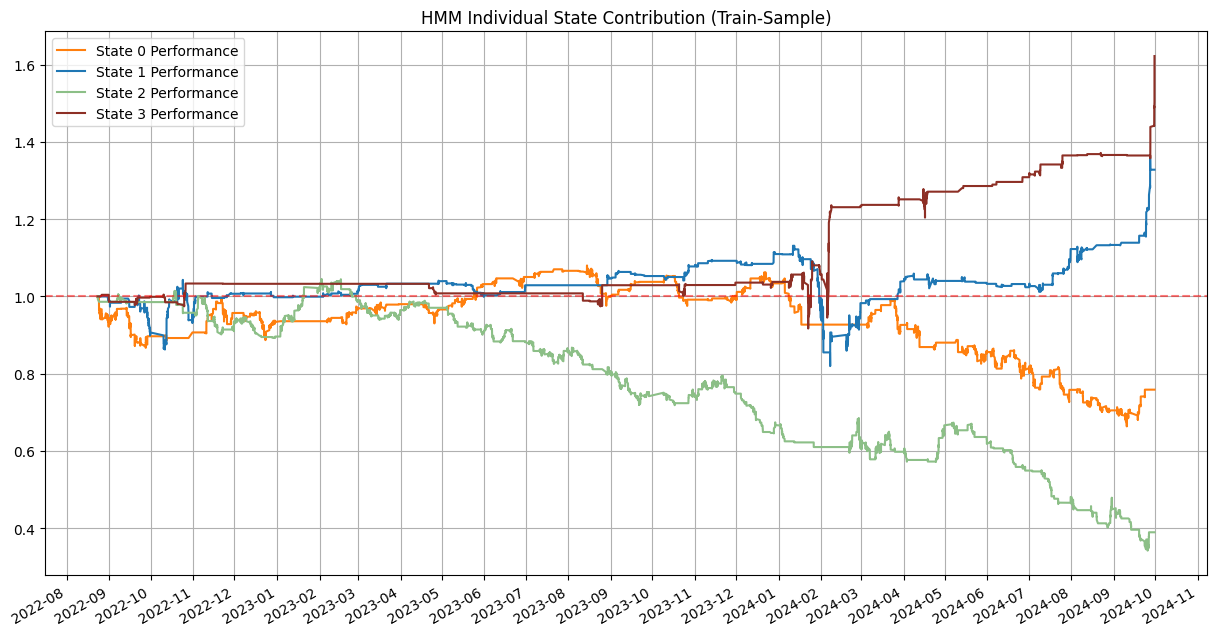

In [20]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(4):
    df_train_sample = df_train_plot.copy()
    net = df_train_sample['pct'].astype(float).values
    signal = (df_train_sample['state'] == i).astype(float).values
    # 计算策略收益序列
    net_values, _ = cal_net_values(signal, net)
    plot_dates = df_train_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("HMM Individual State Contribution (Train-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

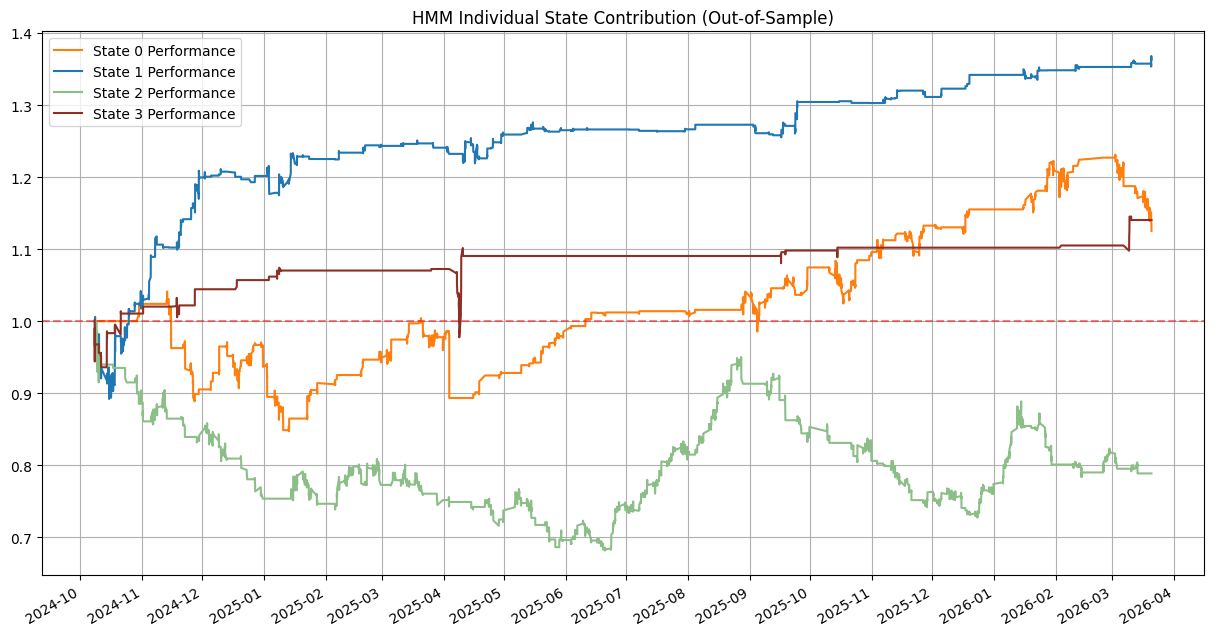

In [21]:
colors = ['#ff7f0e', '#1f77b4', "#8CBF87", "#8D2F25", "#909291", "#4E1945", "#B7B7Eb"]
plt.figure(figsize=(15, 8))
for i in range(4):
    df_test_sample = df_test_plot.copy()
    net = df_test_sample['pct'].astype(float).values
    signal = (df_test_sample['state'] == i).astype(float).values
    net_values, _ = cal_net_values(signal, net) 
    plot_dates = df_test_sample.index
    plt.plot(plot_dates, net_values, color=colors[i], label=f'State {i} Performance')

plt.axhline(1, color='red', linestyle='--', alpha=0.5) #基准线
plt.title("HMM Individual State Contribution (Out-of-Sample)")
plt.legend()
plt.grid(True)
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gcf().autofmt_xdate()
plt.show()

## 4.1 Save Data

In [22]:
df_test = df_test_plot.copy()
df_test.index = pd.to_datetime(df_test.index)

# 确保两者的 index 都是 DateTime 类型
df_im = pd.read_csv("../data/factor_values_norm_im.csv")
df_im.set_index('DateTime', inplace=True)
df_im.index = pd.to_datetime(df_im.index)
df_im = df_im.replace([float('inf'), float('-inf')], 0)
df_im = df_im.fillna(0)
# how='left' 表示以 df1 为准，保留 df1 的所有时间戳
df_im = df_im.drop(columns=['pct', 'state','state_0_prob','state_1_prob','state_2_prob','state_3_prob'], errors='ignore')
result = df_im.join(df_test[['pct', 'state','state_0_prob','state_1_prob','state_2_prob','state_3_prob']], how='left')
result.to_csv("../data/factor_values_norm_im.csv")

# 5. Combinatorial Purged Cross-Validation (CPCV)

## 5.1 CPCV Input

In [ ]:
import math
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cpcv_features = ['ewma_ret', 'dd20', 'dd60', 'dd120', 'dd20_60', 'dd60_120', 'dd20_120', 'f1', 'f2', 'return', 'f4', 'f5']
cpcv_n_groups = 6
cpcv_k_test = 2
cpcv_n_states = 4
cpcv_purge_ticks = 0       # 额外删除测试事件区间两侧的 bar 数
cpcv_embargo_ticks = 0     # 测试事件终点后额外隔离的 bar 数
cpcv_fee = 0.0005          # 每单位换手费用；0 表示查看毛收益
cpcv_data_dir = Path('../data')
cpcv_model_params = {'lam': 150, 'max_iter': 1000}

cpcv_phi = math.comb(cpcv_n_groups - 1, cpcv_k_test - 1)
cpcv_df = df_min.reset_index().copy()
cpcv_df['DateTime'] = pd.to_datetime(cpcv_df['DateTime'])
cpcv_df = cpcv_df.sort_values('DateTime').reset_index(drop=True)
cpcv_df['_pos'] = np.arange(len(cpcv_df))
cpcv_df['_label_end_pos'] = cpcv_df['_pos'] + 1
cpcv_df['return_end'] = cpcv_df['DateTime'].shift(-1)
valid = np.isfinite(cpcv_df[cpcv_features + ['pct']]).all(axis=1)
cpcv_df = cpcv_df.loc[valid & cpcv_df['return_end'].notna()].reset_index(drop=True)
cpcv_df[['DateTime', 'pct', 'return_end'] + cpcv_features].head()


## 5.2 Time Groups

In [ ]:
# np.array_split 只拆分行号，不把 DataFrame 转成 ndarray。
cpcv_df['_group'] = -1
for group_id, row_ids in enumerate(np.array_split(np.arange(len(cpcv_df)), cpcv_n_groups)):
    cpcv_df.loc[row_ids, '_group'] = group_id

cpcv_group_summary = cpcv_df.groupby('_group').agg(
    start_time=('DateTime', 'min'), end_time=('DateTime', 'max'),
    start_pos=('_pos', 'min'), end_pos=('_pos', 'max'),
    event_end_pos=('_label_end_pos', 'max'), samples=('_pos', 'size'),
)
cpcv_group_summary


## 5.3 Purging & Embargo

In [ ]:
cpcv_splits = []
split_summary = []
for split_id, test_groups in enumerate(combinations(range(cpcv_n_groups), cpcv_k_test)):
    test_mask = cpcv_df['_group'].isin(test_groups).to_numpy()
    train_mask = ~test_mask
    for group_id in test_groups:
        interval = cpcv_group_summary.loc[group_id]
        start = int(interval['start_pos'])
        end = int(interval['event_end_pos'])
        overlap = ((cpcv_df['_pos'] <= end + cpcv_purge_ticks)
                   & (cpcv_df['_label_end_pos'] >= start - cpcv_purge_ticks))
        embargo = ((cpcv_df['_pos'] > end)
                   & (cpcv_df['_pos'] <= end + cpcv_embargo_ticks))
        train_mask &= ~(overlap | embargo).to_numpy()
    train_idx = np.flatnonzero(train_mask)
    test_idx = np.flatnonzero(test_mask)
    cpcv_splits.append((train_idx, test_idx))
    split_summary.append({'split_id': split_id, 'test_groups': test_groups,
                          'train_rows': len(train_idx), 'test_rows': len(test_idx),
                          'removed_train_rows': int((~test_mask).sum() - len(train_idx))})
cpcv_split_summary = pd.DataFrame(split_summary)
cpcv_split_summary


## 5.4 Feature Standardization

In [ ]:
def cpcv_sequence_lengths(frame):
    breaks = np.flatnonzero(np.diff(frame['_pos'].to_numpy()) != 1) + 1
    return np.diff(np.r_[0, breaks, len(frame)]).astype(int).tolist()

train_idx, test_idx = cpcv_splits[0]
cpcv_train = cpcv_df.iloc[train_idx].copy()
cpcv_test = cpcv_df.iloc[test_idx].copy()
train_mean = cpcv_train[cpcv_features].mean()
train_std = cpcv_train[cpcv_features].std(ddof=0).replace(0, 1.0)
cpcv_train_norm = (cpcv_train[cpcv_features] - train_mean) / train_std
cpcv_test_norm = (cpcv_test[cpcv_features] - train_mean) / train_std
train_lengths = cpcv_sequence_lengths(cpcv_train)
test_lengths = cpcv_sequence_lengths(cpcv_test)
cpcv_train_norm.head()


## 5.5 Model Training & Prediction

In [ ]:
from cpcv import fit_sjm, predict_test_set


In [ ]:
cpcv_predictions = []
cpcv_state_maps = []
for split_id, (train_idx, test_idx) in enumerate(cpcv_splits):
    cpcv_train = cpcv_df.iloc[train_idx].copy()
    cpcv_test = cpcv_df.iloc[test_idx].copy()
    train_mean = cpcv_train[cpcv_features].mean()
    train_std = cpcv_train[cpcv_features].std(ddof=0).replace(0, 1.0)
    X_train = ((cpcv_train[cpcv_features] - train_mean) / train_std).to_numpy()
    X_test = ((cpcv_test[cpcv_features] - train_mean) / train_std).to_numpy()
    train_lengths = cpcv_sequence_lengths(cpcv_train)
    test_lengths = cpcv_sequence_lengths(cpcv_test)

    raw_train_states, fold_theta, fold_costs = fit_sjm(
            X_train, K=cpcv_n_states, lengths=train_lengths, **cpcv_model_params
    )
    raw_test_states = predict_test_set(
            X_test, fold_theta, cpcv_model_params['lam'], lengths=test_lengths
    )

    train_state_returns = pd.DataFrame({
        'raw_state': raw_train_states, 'pct': cpcv_train['pct'].to_numpy(),
    }).groupby('raw_state')['pct'].sum().reindex(range(cpcv_n_states), fill_value=0.0)
    ordered_states = train_state_returns.sort_values(kind='stable').index
    state_map = pd.Series(np.arange(cpcv_n_states), index=ordered_states)
    cpcv_state_maps.append(pd.DataFrame({
        'split_id': split_id, 'raw_state': state_map.index,
        'state': state_map.to_numpy(), 'train_gross_return': train_state_returns.loc[ordered_states].to_numpy(),
    }))
    pred = cpcv_test[['DateTime', '_pos', '_group']].copy()
    pred['split_id'] = split_id
    pred['raw_state'] = raw_test_states
    pred['state'] = state_map.loc[raw_test_states].to_numpy()
    cpcv_predictions.append(pred)
    print(f'完成第 {split_id + 1}/{len(cpcv_splits)} 折，训练 {len(cpcv_train)} 行，测试 {len(cpcv_test)} 行')

cpcv_signals = pd.concat(cpcv_predictions, ignore_index=True)
cpcv_state_maps = pd.concat(cpcv_state_maps, ignore_index=True)
cpcv_signals.head()


## 5.6 Save Signals & Build Paths

In [ ]:
cpcv_data_dir.mkdir(parents=True, exist_ok=True)
cpcv_signal_file = cpcv_data_dir / 'cpcv_jm_signals.csv'
cpcv_signals.to_csv(cpcv_signal_file, index=False)

cpcv_signals = pd.read_csv(cpcv_signal_file, parse_dates=['DateTime'])
assignments = cpcv_signals[['split_id', '_group']].drop_duplicates().sort_values(['_group', 'split_id'])
assignments['path_id'] = assignments.groupby('_group').cumcount()
cpcv_signals = cpcv_signals.merge(assignments, on=['split_id', '_group'], validate='many_to_one')
cpcv_path_data = cpcv_signals.merge(
    cpcv_df[['DateTime', '_pos', '_group', 'pct', 'return_end']],
    on=['DateTime', '_pos', '_group'], validate='many_to_one',
)
backtest_paths = {}
for path_id in range(cpcv_phi):
    frame = cpcv_path_data.loc[cpcv_path_data['path_id'].eq(path_id)].sort_values('_pos')
    backtest_paths[path_id] = frame.set_index('DateTime').copy()
backtest_paths[0].head()


## 5.7 CPCV State Contribution & Returns

In [ ]:
cpcv_metrics = []
for path_id, df_path in backtest_paths.items():
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
    nav_dates = pd.DatetimeIndex([df_path.index[0], *df_path['return_end']])
    for state_id in range(cpcv_n_states):
        position = df_path['state'].eq(state_id).astype(float)
        turnover = position.diff().fillna(position.iloc[0]).abs()
        strategy_ret = position * df_path['pct'] - turnover * cpcv_fee
        net_values = np.r_[1.0, 1.0 + strategy_ret.cumsum().to_numpy()]
        daily_ret = strategy_ret.groupby(df_path['return_end'].dt.normalize().to_numpy()).sum()
        daily_std = daily_ret.std(ddof=0)
        sharpe = daily_ret.mean() / daily_std * np.sqrt(252) if daily_std > 0 else np.nan
        drawdown = net_values - np.maximum.accumulate(net_values)
        cpcv_metrics.append({'path_id': path_id, 'state': state_id,
                             'total_return': strategy_ret.sum(),
                             'max_drawdown_fixed_capital': drawdown.min(), 'daily_sharpe': sharpe})
        axes[0].plot(nav_dates, net_values, label=f'State {state_id}')
        axes[1].plot(df_path['return_end'], strategy_ret, label=f'State {state_id}', linewidth=0.8)
    axes[0].axhline(1, color='grey', linestyle='--')
    axes[1].axhline(0, color='grey', linestyle='--')
    axes[0].set_title(f'CPCV Path {path_id}: State Net Values (Additive)')
    axes[1].set_title(f'State Returns | fee={cpcv_fee}')
    for ax in axes:
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend()
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
cpcv_metrics = pd.DataFrame(cpcv_metrics)
cpcv_metrics
